In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

%matplotlib inline
mpl.rcParams['font.size']    = 8.0
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family']  = 'Arial'

project_root = os.getcwd()
os.chdir('./dataFolder/load_intan_rhd_format/')
if 'load_intan_rhd_format' in sys.modules:
    del sys.modules['load_intan_rhd_format']
if 'intanutil' in sys.modules:
    del sys.modules['intanutil']
from load_intan_rhd_format import read_data
os.chdir(project_root)
print('read_data loaded OK:', read_data)

read_data loaded OK: <function read_data at 0x137ae3d80>


In [2]:
Fs = 30000

moth_to_channel = {
    'm11_wn2': 'A-015', 'm23_wn2': 'A-001', 'm29_wn2': 'A-027',
    'm30_wn1': 'A-007', 'm31_wn2': 'A-029'}

moth = 'm31_wn2'
rhd_path   = './dataFolder/1_RHD_Files/m31_wn2.rhd'
spike_path = './dataFolder/2_Spikesorted_Files/m31_wn2_14.txt'

result = read_data(rhd_path)

target = moth_to_channel[moth]
ch_idx = next(i for i, ch in enumerate(result['amplifier_channels'])
             if ch['native_channel_name'] == target)
voltage = result['amplifier_data'][ch_idx]
print(f'using channel {target} (index {ch_idx}), trace length {len(voltage)/Fs:.1f} s')

T = pd.read_csv(spike_path, delimiter=r'\s+')
units = sorted(u for u in T['Unit'].unique() if u != 0)   # exclude unit_0
print('units present (excl. unit_0):', units)


Reading Intan Technologies RHD Data File, Version 1.5

Found 16 amplifier channels.
Found 0 auxiliary input channels.
Found 0 supply voltage channels.
Found 1 board ADC channel.
Found 1 board digital input channel.
Found 0 board digital output channels.
Found 0 temperature sensors channels.

File contains 361.664 seconds of data.  Amplifiers were sampled at 30.00 kS/s.

Allocating memory for data...
Reading data from file...
10% done...
20% done...
30% done...
40% done...
50% done...
60% done...
70% done...
80% done...
90% done...
Parsing data...
Done!  Elapsed time: 8.9 seconds
using channel A-029 (index 13), trace length 361.7 s
units present (excl. unit_0): [np.int64(1), np.int64(2), np.int64(3)]


In [3]:
index = pd.read_csv('./dataFolder/3_ReadRHD_files/m31_wn2_index.csv')
window = 5.0

found = None
for _, row in index.iterrows():
    rep_start_s = row['index_starts'] / Fs
    for w_start in [rep_start_s, rep_start_s + window]:
        w_stop = w_start + window
        in_window = T[(T['Timestamp'] >= w_start) & (T['Timestamp'] < w_stop)]
        if set(in_window['Unit']) - {0} == set(units):
            found = (w_start, w_stop)
            break
    if found:
        break

if found is None:
    raise ValueError('no 5s window found with all 3 units firing')

w_start, w_stop = found
print(f'window: {w_start:.2f}s to {w_stop:.2f}s')

window: 1.04s to 6.04s


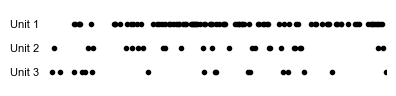

In [33]:
fig_raster, ax_raster = plt.subplots(figsize=(4, 1))

for i, u in enumerate(units):
    st = T.loc[T['Unit'] == u, 'Timestamp'].values
    st = st[(st >= w_start) & (st < w_stop)] - w_start
    ax_raster.plot(st, [len(units) - i] * len(st), 'o', color='black',
                   markersize=3, zorder=3, linestyle='none', rasterized=True)

ax_raster.set_yticks(range(1, len(units) + 1))
ax_raster.set_yticklabels([f'Unit {u}' for u in reversed(units)], fontsize=8)
ax_raster.set_xlim(0, window)
ax_raster.set_ylim(0.4, len(units) + 0.6)

for spine in ax_raster.spines.values():
    spine.set_visible(False)
ax_raster.tick_params(left=False, bottom=False, labelbottom=False)

plt.tight_layout()
out_fig_raster = './dataFolder/Figures/RawTrace_m31_wn2_raster.pdf'
fig_raster.savefig(out_fig_raster, bbox_inches='tight', dpi=600)
plt.show()

trace range: 238.3 µV   →   scale bar: 100 µV


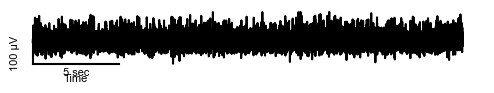

In [36]:
fig_trace, ax_trace = plt.subplots(figsize=(5, 1))

ax_trace.plot(t_win, trace_win, color='black', linewidth=1.5)
ax_trace.axis('off')

y0 = trace_win.min()
signal_range = trace_win.max() - trace_win.min()
raw_scale = signal_range / 4
magnitude = 10 ** np.floor(np.log10(raw_scale))
for step in [1, 2, 5, 10]:
    candidate = step * magnitude
    if candidate >= raw_scale:
        yscale = candidate
        break
print(f'trace range: {signal_range:.1f} µV   →   scale bar: {yscale:.0f} µV')

ax_trace.plot([0, 0], [y0, y0 + yscale], color='black', linewidth=1.5)
ax_trace.text(-0.15, y0 + yscale/2, f'{yscale:.0f} µV', rotation=90, ha='right', va='center', fontsize=8)

xbar_len = 1.0
ax_trace.plot([0, xbar_len], [y0, y0], color='black', linewidth=1.5)
ax_trace.text(xbar_len/2, y0 - signal_range*0.08, '5 sec', ha='center', va='top', fontsize=8)
ax_trace.text(xbar_len/2, y0 - signal_range*0.18, 'Time', ha='center', va='top', fontsize=8)

plt.tight_layout()
out_fig_trace = './dataFolder/Figures/RawTrace_m31_wn2_waveform.pdf'
fig_trace.savefig(out_fig_trace, bbox_inches='tight', dpi=600)
plt.show()